# Switching Costs

This notebook separates two different switching-cost sources. The first plot shows the embedded GPT-2 default K-bar/fallback values used by the carbon-savings simulator. The measured benchmark section below shows a source-target transition matrix, with the benchmark model and topology disclosed explicitly.

In [1]:
from __future__ import annotations

import csv
from collections import defaultdict
from pathlib import Path
from statistics import mean, stdev

import matplotlib.pyplot as plt
import numpy as np

try:
    import pandas as pd
except ImportError:
    pd = None

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "runs").exists():
    REPO_ROOT = REPO_ROOT.parent

def sample_std(values):
    return stdev(values) if len(values) > 1 else 0.0

def cfg_label(config):
    fields = {part[:2].upper(): part[2:] for part in config.split("_")}
    return f"DP{fields['DP']} TP{fields['TP']} PP{fields['PP']}"

plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "-",
})

## Embedded GPT-2 Default K-bar

This plot parses the embedded GPT-2 default `reshard_wall_time_s` values directly from `src/carbon_aware_3d/carbon_aware_env.py`. Their mean is the rounded `64.58s` switch-time fallback used by the simulator and switch-cost sweep.

Embedded GPT-2 default reshard mean: 64.575s
Embedded GPT-2 default reshard std:  19.851s
Rounded fallback switch_time_s:       64.58s


,label,tp,pp,dp,reshard_wall_time_s
0,DP8 TP1 PP1,1,1,8,66.1
1,DP4 TP1 PP2,1,2,4,99.2
2,DP2 TP1 PP4,1,4,2,76.0
3,DP4 TP2 PP1,2,1,4,34.3
4,DP2 TP2 PP2,2,2,2,62.8
5,DP1 TP2 PP4,2,4,1,47.8
6,DP2 TP4 PP1,4,1,2,54.6
7,DP1 TP4 PP2,4,2,1,75.8


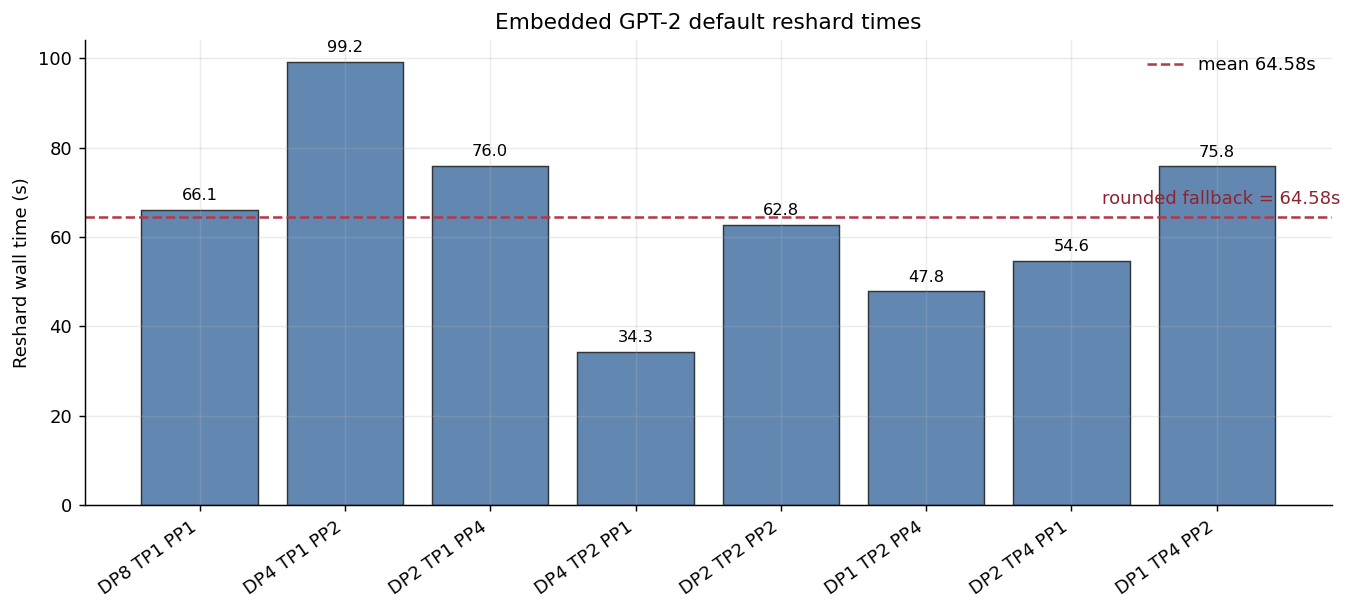

In [2]:
import ast

carbon_env_py = REPO_ROOT / "src" / "carbon_aware_3d" / "carbon_aware_env.py"
carbon_env_ast = ast.parse(carbon_env_py.read_text())
default_strategies = None
for node in carbon_env_ast.body:
    is_default_strategies = isinstance(node, ast.Assign) and any(
        isinstance(target, ast.Name) and target.id == "DEFAULT_STRATEGIES"
        for target in node.targets
    )
    if is_default_strategies:
        default_strategies = ast.literal_eval(node.value)
        break

if default_strategies is None:
    raise RuntimeError(f"Could not find DEFAULT_STRATEGIES in {carbon_env_py}")

embedded_gpt2_default_switch_costs = []
for row in default_strategies:
    if "reshard_wall_time_s" not in row:
        continue
    tp = int(row["tp"])
    pp = int(row["pp"])
    dp = int(row["dp"])
    embedded_gpt2_default_switch_costs.append(
        {
            "label": f"DP{dp} TP{tp} PP{pp}",
            "tp": tp,
            "pp": pp,
            "dp": dp,
            "reshard_wall_time_s": float(row["reshard_wall_time_s"]),
        }
    )

embedded_switch_values = [row["reshard_wall_time_s"] for row in embedded_gpt2_default_switch_costs]
embedded_switch_mean = mean(embedded_switch_values)
embedded_switch_std = sample_std(embedded_switch_values)

print(f"Embedded GPT-2 default reshard mean: {embedded_switch_mean:.3f}s")
print(f"Embedded GPT-2 default reshard std:  {embedded_switch_std:.3f}s")
print(f"Rounded fallback switch_time_s:       {embedded_switch_mean:.2f}s")

if pd is not None:
    display(pd.DataFrame(embedded_gpt2_default_switch_costs).round(3))
else:
    for row in embedded_gpt2_default_switch_costs:
        print(row)

fig, ax = plt.subplots(figsize=(10.5, 4.8))
x = np.arange(len(embedded_gpt2_default_switch_costs))
vals = np.array(embedded_switch_values)
labels = [row["label"] for row in embedded_gpt2_default_switch_costs]

bars = ax.bar(x, vals, color="#4c78a8", edgecolor="#222222", linewidth=0.8, alpha=0.88)
ax.axhline(
    embedded_switch_mean,
    color="#b23a48",
    linestyle="--",
    linewidth=1.4,
    label=f"mean {embedded_switch_mean:.2f}s",
)

for bar, val in zip(bars, vals):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        val + 1.5,
        f"{val:.1f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax.text(
    len(vals) - 0.15,
    embedded_switch_mean + 2.0,
    f"rounded fallback = {embedded_switch_mean:.2f}s",
    ha="right",
    va="bottom",
    color="#8f2330",
    fontsize=10,
)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=35, ha="right")
ax.set_ylabel("Reshard wall time (s)")
ax.set_title("Embedded GPT-2 default reshard times")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()


## Measured Transition Benchmark

Each cell below is one directional transition `source strategy -> target strategy` from `results/resharding/reshard_times.csv`. This is a separate 4-GPU benchmark source, not the embedded 8-GPU GPT-2 fallback table above.

In [3]:
import ast

reshard_csv = REPO_ROOT / "results" / "resharding" / "reshard_times.csv"
benchmark_script = REPO_ROOT / "scripts" / "benchmarks" / "benchmark_inner.py"

script_tree = ast.parse(benchmark_script.read_text())
script_literals = {}
for node in script_tree.body:
    if isinstance(node, ast.Assign) and len(node.targets) == 1 and isinstance(node.targets[0], ast.Name):
        try:
            script_literals[node.targets[0].id] = ast.literal_eval(node.value)
        except Exception:
            pass

benchmark_world_size = int(script_literals.get("N", 4))
benchmark_num_layers = int(script_literals.get("NUM_LAYERS", 24))
benchmark_hidden_size = int(script_literals.get("HIDDEN_SIZE", 2048))
benchmark_num_heads = int(script_literals.get("NUM_HEADS", 16))
benchmark_seq_len = int(script_literals.get("SEQ_LEN", 1024))
benchmark_micro_batch = int(script_literals.get("MICRO_BATCH", 2))
benchmark_global_batch = int(script_literals.get("GLOBAL_BATCH", 8))
benchmark_warmup_steps = int(script_literals.get("WARMUP_STEPS", 50))
benchmark_resume_steps = int(script_literals.get("RESUME_STEPS", 5))

benchmark_model_label = (
    f"GPT ~1.3B ({benchmark_num_layers} layers, hidden {benchmark_hidden_size}, "
    f"{benchmark_num_heads} heads, seq {benchmark_seq_len})"
)
benchmark_topology_label = (
    f"single-node {benchmark_world_size}x L40, "
    f"torchrun --nproc_per_node={benchmark_world_size}"
)
benchmark_run_label = (
    f"mock data, micro batch {benchmark_micro_batch}, global batch {benchmark_global_batch}, "
    f"warmup {benchmark_warmup_steps} steps, resume {benchmark_resume_steps} steps"
)

with reshard_csv.open(newline="") as f:
    benchmark_rows = list(csv.DictReader(f))

int_cols = ["from_dp", "from_tp", "from_pp", "to_dp", "to_tp", "to_pp"]
float_cols = ["reshard_s", "wall_clock_s", "avg_iter_ms", "output_mb"]
for row in benchmark_rows:
    for col in int_cols:
        row[col] = int(row[col])
    for col in float_cols:
        row[col] = float(row[col])
    row["from_label"] = cfg_label(row["from_config"])
    row["to_label"] = cfg_label(row["to_config"])
    row["transition"] = f"{row['from_label']} -> {row['to_label']}"
    row["transition_tick"] = f"{row['from_label']}\n-> {row['to_label']}"
    row["from_world_size"] = row["from_dp"] * row["from_tp"] * row["from_pp"]
    row["to_world_size"] = row["to_dp"] * row["to_tp"] * row["to_pp"]

world_sizes = sorted({row["from_world_size"] for row in benchmark_rows} | {row["to_world_size"] for row in benchmark_rows})
if world_sizes != [benchmark_world_size]:
    raise ValueError(
        f"CSV world sizes {world_sizes} do not match benchmark script N={benchmark_world_size}"
    )

all_switch_costs = [row["reshard_s"] for row in benchmark_rows]
overall_mean = mean(all_switch_costs)
overall_std = sample_std(all_switch_costs)
transition_rows = sorted(benchmark_rows, key=lambda row: row["reshard_s"], reverse=True)

print(f"Loaded {len(all_switch_costs)} measured transitions from {reshard_csv.relative_to(REPO_ROOT)}")
print(f"Benchmark model:   {benchmark_model_label}")
print(f"Benchmark topology: {benchmark_topology_label}")
print(f"Benchmark setup:   {benchmark_run_label}")
print(f"Overall measured transition cost: mean={overall_mean:.3f}s, std={overall_std:.3f}s")

transition_summary_cols = [
    "transition", "reshard_s", "wall_clock_s", "avg_iter_ms", "output_mb",
    "from_config", "to_config",
]
if pd is not None:
    display(pd.DataFrame(transition_rows)[transition_summary_cols].round(3))
else:
    for row in transition_rows:
        print({col: row[col] for col in transition_summary_cols})


Loaded 19 measured transitions from results/resharding/reshard_times.csv
Benchmark model:   GPT ~1.3B (24 layers, hidden 2048, 16 heads, seq 1024)
Benchmark topology: single-node 4x L40, torchrun --nproc_per_node=4
Benchmark setup:   mock data, micro batch 2, global batch 8, warmup 50 steps, resume 5 steps
Overall measured transition cost: mean=14.325s, std=4.430s


,transition,reshard_s,wall_clock_s,avg_iter_ms,output_mb,from_config,to_config
0,DP1 TP1 PP4 -> DP4 TP1 PP1,23.48,340.86,672.96,18394.5,dp1_tp1_pp4,dp4_tp1_pp1
1,DP2 TP1 PP2 -> DP1 TP1 PP4,21.11,294.77,946.12,18394.6,dp2_tp1_pp2,dp1_tp1_pp4
2,DP1 TP2 PP2 -> DP4 TP1 PP1,21.06,339.51,666.18,18394.5,dp1_tp2_pp2,dp4_tp1_pp1
3,DP1 TP4 PP1 -> DP4 TP1 PP1,18.23,342.44,668.60,18394.5,dp1_tp4_pp1,dp4_tp1_pp1
4,DP2 TP1 PP2 -> DP2 TP2 PP1,17.07,313.10,643.12,18399.3,dp2_tp1_pp2,dp2_tp2_pp1
5,DP1 TP1 PP4 -> DP2 TP2 PP1,16.82,330.87,629.18,18399.3,dp1_tp1_pp4,dp2_tp2_pp1
6,DP1 TP4 PP1 -> DP1 TP1 PP4,16.02,318.48,952.92,18394.6,dp1_tp4_pp1,dp1_tp1_pp4
7,DP2 TP1 PP2 -> DP1 TP4 PP1,14.73,337.11,733.16,18408.8,dp2_tp1_pp2,dp1_tp4_pp1
8,DP1 TP1 PP4 -> DP1 TP4 PP1,14.63,310.09,728.52,18408.8,dp1_tp1_pp4,dp1_tp4_pp1
9,DP1 TP2 PP2 -> DP1 TP1 PP4,13.22,320.63,971.82,18394.6,dp1_tp2_pp2,dp1_tp1_pp4


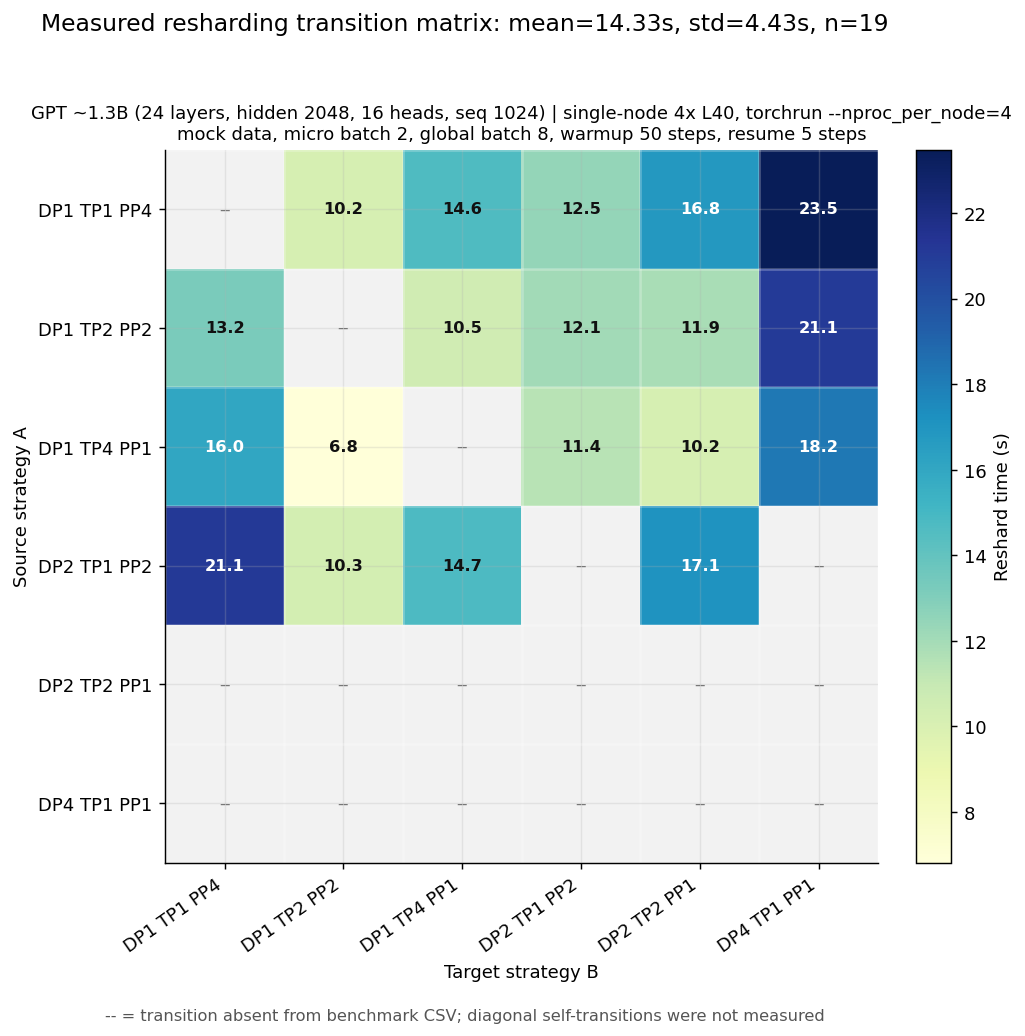

In [4]:
def _config_key(config):
    fields = {part[:2].upper(): int(part[2:]) for part in config.split("_")}
    return fields["DP"], fields["TP"], fields["PP"]

strategy_label_by_config = {}
for row in benchmark_rows:
    strategy_label_by_config[row["from_config"]] = row["from_label"]
    strategy_label_by_config[row["to_config"]] = row["to_label"]

strategy_configs = sorted(strategy_label_by_config, key=_config_key)
strategy_labels = [strategy_label_by_config[config] for config in strategy_configs]
strategy_index = {label: i for i, label in enumerate(strategy_labels)}

matrix = np.full((len(strategy_labels), len(strategy_labels)), np.nan)
for row in benchmark_rows:
    source_i = strategy_index[row["from_label"]]
    target_j = strategy_index[row["to_label"]]
    matrix[source_i, target_j] = row["reshard_s"]

fig, ax = plt.subplots(figsize=(8.8, 7.6))
cmap = plt.get_cmap("YlGnBu").copy()
cmap.set_bad("#f2f2f2")
image = ax.imshow(np.ma.masked_invalid(matrix), cmap=cmap, aspect="equal")

cbar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Reshard time (s)")

ax.set_xticks(np.arange(len(strategy_labels)))
ax.set_yticks(np.arange(len(strategy_labels)))
ax.set_xticklabels(strategy_labels, rotation=35, ha="right")
ax.set_yticklabels(strategy_labels)
ax.set_xlabel("Target strategy B")
ax.set_ylabel("Source strategy A")

ax.set_xticks(np.arange(-0.5, len(strategy_labels), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(strategy_labels), 1), minor=True)
ax.grid(which="minor", color="#ffffff", linewidth=1.5)
ax.tick_params(which="minor", bottom=False, left=False)

valid_values = matrix[~np.isnan(matrix)]
text_threshold = (float(valid_values.min()) + float(valid_values.max())) / 2.0
for i in range(len(strategy_labels)):
    for j in range(len(strategy_labels)):
        value = matrix[i, j]
        if np.isnan(value):
            label = "--"
            color = "#777777"
            weight = "normal"
        else:
            label = f"{value:.1f}"
            color = "#ffffff" if value > text_threshold else "#111111"
            weight = "bold"
        ax.text(j, i, label, ha="center", va="center", color=color, fontsize=9, fontweight=weight)

ax.set_title(
    f"{benchmark_model_label} | {benchmark_topology_label}\n"
    f"{benchmark_run_label}",
    fontsize=10,
)
fig.suptitle(
    f"Measured resharding transition matrix: mean={overall_mean:.2f}s, "
    f"std={overall_std:.2f}s, n={len(transition_rows)}",
    y=1.03,
    fontsize=13,
)
fig.text(0.5, 0.01, "-- = transition absent from benchmark CSV; diagonal self-transitions were not measured", ha="center", fontsize=9, color="#555555")
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()
